# Gaussian Bayes Classifier

I implemented QDA, LDA, and Gaussian Naive Bayes in NumPy. The tests compare fitted parameters, probabilities, and predictions with scikit-learn on synthetic data.

### Test Bench

In [4]:
%load_ext autoreload
%autoreload 2
# No need to restart the notebook upon change thanks to autoreload
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis

from BayesClassifier import BayesClassifier

#### Generate Synthetic Data

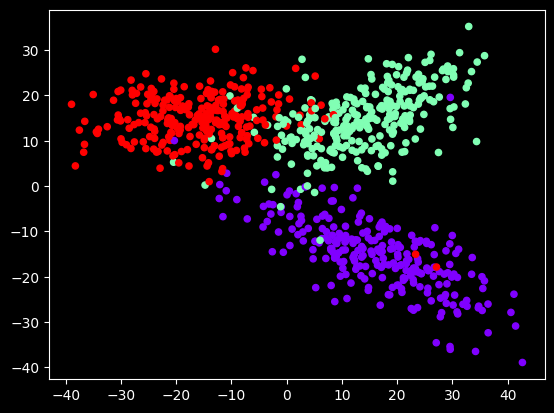

In [5]:
# Generate synthetic data
X, y = make_classification(n_samples=1000, n_features=2, n_classes=3, n_clusters_per_class=1, 
                           random_state=0,  n_informative=2, n_redundant=0, class_sep=1.5, scale=10)
x_train, x_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Plot the data
plt.style.use('dark_background')
plt.scatter(x_train[:, 0], x_train[:, 1], c=y_train, s=20, cmap='rainbow')
plt.show()

#### Testing Normal Distribution

#### 1) Testing QDA

1.1 Fits without errors

In [6]:
my_classifier = BayesClassifier(mode='QDA')
my_classifier.fit(x_train, y_train)

1.2 Test basic properties of parameters

In [7]:
assert len(my_classifier.means) == len(my_classifier.labels)
assert my_classifier.means[0].shape == (2,)
assert len(my_classifier.covs) == len(my_classifier.labels)
assert my_classifier.covs[0].shape == (2,2)
assert len(my_classifier.priors) == len(my_classifier.labels)
assert my_classifier.priors.sum() == 1
assert my_classifier.weighted_cov == None

1.3 Test that parameters are set correctly

In [8]:
# compare with scikit parameters
clf = QuadraticDiscriminantAnalysis(store_covariance=True)
clf.fit(x_train, y_train)
assert np.allclose(my_classifier.means, clf.means_)
assert np.allclose(my_classifier.covs, clf.covariance_)
assert np.allclose(my_classifier.priors, clf.priors_)

1.4 Test the PDF of the Normal Distribution

In [9]:
### Prediction Checks ###
### DO NOT CHANGE THIS CODE ###
np.random.seed(90)
assertion_x = np.random.rand(3)
assertion_mu = np.random.rand(3)
assertion_sigma = np.random.rand(3, 3)
assertion_probability = BayesClassifier.N(assertion_x, assertion_mu, assertion_sigma)
assertion_probability = round(assertion_probability, 1)
assert assertion_probability == 7.8

1.5 Basic test for `predict_proba_x` 

In [10]:
y_pred = my_classifier.predict_proba_x(np.random.rand(2))
assert y_pred.shape == (3,)
assert np.allclose(np.sum(y_pred), 1)

1.6 It follows that `predict_proba` is implemented correctly

In [11]:
assert np.allclose(my_classifier.predict_proba(x_val), clf.predict_proba(x_val))

1.7 Test `predict`

In [12]:
y_pred = my_classifier.predict(x_val)
assert y_pred.shape == y_val.shape
assert np.allclose(y_pred, clf.predict(x_val))

1.8 Test `accuracy`

In [13]:
assert np.allclose(my_classifier.score(x_val, y_val), clf.score(x_val, y_val))

#### 2) Testing LDA

In [14]:
my_classifier = BayesClassifier(mode='LDA')
my_classifier.fit(x_train, y_train)

2.1 Test basic properties of parameters

In [15]:
assert len(my_classifier.means) == len(my_classifier.labels)
assert len(my_classifier.covs) == 0
assert len(my_classifier.priors) == len(my_classifier.labels)
assert my_classifier.priors.sum() == 1

2.2 Test parameter values

In [16]:
clf = LinearDiscriminantAnalysis(solver='eigen', store_covariance=True)
clf.fit(x_train, y_train)
assert np.allclose(my_classifier.weighted_cov, clf.covariance_)
assert np.allclose(my_classifier.means, clf.means_)
assert np.allclose(my_classifier.priors, clf.priors_)

2.3 Basic test for `predict_proba_x` 

In [17]:
y_pred = my_classifier.predict_proba_x(np.random.rand(2,))
assert y_pred.shape == (3,)
assert np.allclose(np.sum(y_pred), 1)

2.4 End-to-end tests

In [18]:
assert np.allclose(my_classifier.predict_proba(x_val), clf.predict_proba(x_val))

y_pred = my_classifier.predict(x_val)
assert y_pred.shape == y_val.shape
assert np.allclose(y_pred, clf.predict(x_val))

assert np.allclose(my_classifier.score(x_val, y_val), clf.score(x_val, y_val))

#### 3) Testing Gaussian Naive Bayes

In [19]:
my_classifier = BayesClassifier(mode='Naive')
my_classifier.fit(x_train, y_train)

3.1 Test basic properties of parameters

In [20]:
assert len(my_classifier.means) == len(my_classifier.labels)
assert len(my_classifier.covs) == len(my_classifier.labels)
assert len(my_classifier.priors) == len(my_classifier.labels)
assert my_classifier.priors.sum() == 1
assert my_classifier.weighted_cov == None

3.2 Test parameter values

In [21]:
clf = GaussianNB()
clf.fit(x_train, y_train)
assert np.allclose(my_classifier.priors, clf.class_prior_)
assert np.allclose(my_classifier.means, clf.theta_)
# loop on each row of clf.var_ and ensure the computed variances for a class are the diagonal of corresponding covariance matrix
for i in range(clf.var_.shape[0]): assert np.allclose(my_classifier.covs[i], np.diag(clf.var_[i]))

3.3 End-to-end test

In [22]:
assert np.allclose(my_classifier.predict_proba(x_val), clf.predict_proba(x_val))

y_pred = my_classifier.predict(x_val)
assert y_pred.shape == y_val.shape
assert np.allclose(y_pred, clf.predict(x_val))

assert np.allclose(my_classifier.score(x_val, y_val), clf.score(x_val, y_val))